# GLiNER medium v2.5: sentence-aware extraction

Reports saved inference on unique fit CV/JD documents. No training or inference is launched here. Model and chunk strategy change together: counts and uncalibrated scores do not establish accuracy or isolate chunking. Fit labels cannot provide entity precision/recall/F1. A1 labels do not reproduce (A13).

In [1]:
from candidate_screener.config import OUTPUT
from candidate_screener.extraction.fit_run import load_campaign as load_baseline
from candidate_screener.extraction.medium_run import load_campaign as load_medium
from candidate_screener.extraction.medium_report import BASELINE_CAMPAIGN_ID, comparison_tables, save_comparison
from candidate_screener.extraction.fit_plots import save_fit_charts
from IPython.display import Image, display

baseline = load_baseline(BASELINE_CAMPAIGN_ID)
medium = load_medium()
tables = comparison_tables(baseline, medium)
report_dir = OUTPUT / "extraction/medium-sentence-comparison"
record = save_comparison(baseline, medium, report_dir)
print(record["baseline_campaign_id"], record["medium_campaign_id"])

901a26c9e785920223b07c9b 3d836f87df64512b057b20ec


## Processing outcomes

All requested documents remain in state denominators. Completed zeros, incomplete, failed and pending states remain distinct. Missing chunk counters are unknown. Each text display is capped at five rows and 2,000 characters. Full aggregate tables are saved to CSV. Only aggregates are displayed: source text, IDs and evidence remain in ignored data. Split populations may share documents; their counts are not additive unique totals.

In [2]:
view = tables["operations"].query("split == 'train' and doc_type == 'cv'")
print(view.drop(columns=[c for c in view if c.endswith("_rate")]).head(5).to_string(index=False)[:1999])

                         model split doc_type  requested_documents  completed_documents  completed_spans  complete  complete_zero  incomplete  failed  pending  runtime_seconds  chunks  fallback_windows  quarantined_spans  sentence_count
     small-v2.1 / word windows train       cv                  446                  446             8622       427             19           0       0        0      1126.975656     NaN               NaN                NaN             NaN
medium-v2.5 / sentence windows train       cv                  446                  446            25176       446              0           0       0        0      2140.381297  1923.0             121.0                0.0         17608.0


In [3]:
view = tables["operations"].query("split == 'train' and doc_type == 'jd'")
print(view.drop(columns=[c for c in view if c.endswith("_rate")]).head(5).to_string(index=False)[:1999])

                         model split doc_type  requested_documents  completed_documents  completed_spans  complete  complete_zero  incomplete  failed  pending  runtime_seconds  chunks  fallback_windows  quarantined_spans  sentence_count
     small-v2.1 / word windows train       jd                  245                  245             1490       235             10           0       0        0       354.560124     NaN               NaN                NaN             NaN
medium-v2.5 / sentence windows train       jd                  245                  245             4504       245              0           0       0        0       421.243372   491.0               4.0                0.0          6161.0


In [4]:
view = tables["operations"].query("split == 'test' and doc_type == 'cv'")
print(view.drop(columns=[c for c in view if c.endswith("_rate")]).head(5).to_string(index=False)[:1999])

                         model split doc_type  requested_documents  completed_documents  completed_spans  complete  complete_zero  incomplete  failed  pending  runtime_seconds  chunks  fallback_windows  quarantined_spans  sentence_count
     small-v2.1 / word windows  test       cv                  158                  158             3205       152              6           0       0        0       399.175454     NaN               NaN                NaN             NaN
medium-v2.5 / sentence windows  test       cv                  158                  158             9488       158              0           0       0        0       738.902939   676.0              42.0                0.0          6385.0


In [5]:
view = tables["operations"].query("split == 'test' and doc_type == 'jd'")
print(view.drop(columns=[c for c in view if c.endswith("_rate")]).head(5).to_string(index=False)[:1999])

                         model split doc_type  requested_documents  completed_documents  completed_spans  complete  complete_zero  incomplete  failed  pending  runtime_seconds  chunks  fallback_windows  quarantined_spans  sentence_count
     small-v2.1 / word windows  test       jd                  100                  100              629        99              1           0       0        0       132.007739     NaN               NaN                NaN             NaN
medium-v2.5 / sentence windows  test       jd                  100                  100             1859       100              0           0       0        0       176.491185   208.0               0.0                0.0          2607.0


## Category coverage and confidence

Label metrics use completed documents only. Operational coverage divides completed evidence support by all requested documents. Missing results do not establish entity absence. Scores are conditional on the frozen threshold, not probabilities of correctness.

In [6]:
view = tables["labels"].loc[(tables["labels"].model == 'small-v2.1 / word windows') & (tables["labels"].split == 'train') & (tables["labels"].doc_type == 'cv')]
print(view.head(5).to_string(index=False)[:1999])

                    model split doc_type            label  requested_documents  completed_documents  spans  covered_completed_documents  operational_coverage  score_min  score_median  score_max
small-v2.1 / word windows train       cv        KNOWLEDGE                  446                  446   6962                          301              0.674888   0.500037      0.670819   0.991134
small-v2.1 / word windows train       cv            SKILL                  446                  446    478                          193              0.432735   0.500204      0.572279   0.843086
small-v2.1 / word windows train       cv            TITLE                  446                  446    914                          287              0.643498   0.500490      0.579686   0.882026
small-v2.1 / word windows train       cv           DEGREE                  446                  446    244                          139              0.311659   0.501621      0.647406   0.925418
small-v2.1 / word windows trai

In [7]:
view = tables["labels"].loc[(tables["labels"].model == 'small-v2.1 / word windows') & (tables["labels"].split == 'train') & (tables["labels"].doc_type == 'jd')]
print(view.head(5).to_string(index=False)[:1999])

                    model split doc_type            label  requested_documents  completed_documents  spans  covered_completed_documents  operational_coverage  score_min  score_median  score_max
small-v2.1 / word windows train       jd        KNOWLEDGE                  245                  245    739                          145              0.591837   0.500017      0.670878   0.975663
small-v2.1 / word windows train       jd            SKILL                  245                  245    171                           91              0.371429   0.502155      0.610747   0.948616
small-v2.1 / word windows train       jd            TITLE                  245                  245    341                          151              0.616327   0.500210      0.639898   0.921161
small-v2.1 / word windows train       jd           DEGREE                  245                  245    208                          125              0.510204   0.501513      0.729076   0.952377
small-v2.1 / word windows trai

In [8]:
view = tables["labels"].loc[(tables["labels"].model == 'small-v2.1 / word windows') & (tables["labels"].split == 'test') & (tables["labels"].doc_type == 'cv')]
print(view.head(5).to_string(index=False)[:1999])

                    model split doc_type            label  requested_documents  completed_documents  spans  covered_completed_documents  operational_coverage  score_min  score_median  score_max
small-v2.1 / word windows  test       cv        KNOWLEDGE                  158                  158   2661                          115              0.727848   0.500169      0.667875   0.971608
small-v2.1 / word windows  test       cv            SKILL                  158                  158    140                           57              0.360759   0.500542      0.592814   0.874171
small-v2.1 / word windows  test       cv            TITLE                  158                  158    315                           93              0.588608   0.500256      0.575864   0.880153
small-v2.1 / word windows  test       cv           DEGREE                  158                  158     83                           51              0.322785   0.501106      0.646969   0.943454
small-v2.1 / word windows  tes

In [9]:
view = tables["labels"].loc[(tables["labels"].model == 'small-v2.1 / word windows') & (tables["labels"].split == 'test') & (tables["labels"].doc_type == 'jd')]
print(view.head(5).to_string(index=False)[:1999])

                    model split doc_type            label  requested_documents  completed_documents  spans  covered_completed_documents  operational_coverage  score_min  score_median  score_max
small-v2.1 / word windows  test       jd        KNOWLEDGE                  100                  100    335                           56                  0.56   0.500130      0.672558   0.965159
small-v2.1 / word windows  test       jd            SKILL                  100                  100     57                           36                  0.36   0.500946      0.589400   0.802101
small-v2.1 / word windows  test       jd            TITLE                  100                  100    145                           74                  0.74   0.503028      0.596956   0.934874
small-v2.1 / word windows  test       jd           DEGREE                  100                  100     83                           54                  0.54   0.510636      0.737267   0.952802
small-v2.1 / word windows  tes

In [10]:
view = tables["labels"].loc[(tables["labels"].model == 'medium-v2.5 / sentence windows') & (tables["labels"].split == 'train') & (tables["labels"].doc_type == 'cv')]
print(view.head(5).to_string(index=False)[:1999])

                         model split doc_type            label  requested_documents  completed_documents  spans  covered_completed_documents  operational_coverage  score_min  score_median  score_max
medium-v2.5 / sentence windows train       cv        KNOWLEDGE                  446                  446  17989                          427              0.957399   0.500001      0.733576   0.989064
medium-v2.5 / sentence windows train       cv            SKILL                  446                  446   1920                          396              0.887892   0.500166      0.593711   0.913468
medium-v2.5 / sentence windows train       cv            TITLE                  446                  446   3884                          442              0.991031   0.500162      0.696709   0.967107
medium-v2.5 / sentence windows train       cv           DEGREE                  446                  446   1190                          361              0.809417   0.500541      0.726410   0.989886
mediu

In [11]:
view = tables["labels"].loc[(tables["labels"].model == 'medium-v2.5 / sentence windows') & (tables["labels"].split == 'train') & (tables["labels"].doc_type == 'jd')]
print(view.head(5).to_string(index=False)[:1999])

                         model split doc_type            label  requested_documents  completed_documents  spans  covered_completed_documents  operational_coverage  score_min  score_median  score_max
medium-v2.5 / sentence windows train       jd        KNOWLEDGE                  245                  245   2210                          231              0.942857   0.500584      0.780655   0.989799
medium-v2.5 / sentence windows train       jd            SKILL                  245                  245    783                          190              0.775510   0.500431      0.607492   0.939363
medium-v2.5 / sentence windows train       jd            TITLE                  245                  245    964                          233              0.951020   0.500004      0.750237   0.962654
medium-v2.5 / sentence windows train       jd           DEGREE                  245                  245    391                          164              0.669388   0.502319      0.852055   0.992177
mediu

In [12]:
view = tables["labels"].loc[(tables["labels"].model == 'medium-v2.5 / sentence windows') & (tables["labels"].split == 'test') & (tables["labels"].doc_type == 'cv')]
print(view.head(5).to_string(index=False)[:1999])

                         model split doc_type            label  requested_documents  completed_documents  spans  covered_completed_documents  operational_coverage  score_min  score_median  score_max
medium-v2.5 / sentence windows  test       cv        KNOWLEDGE                  158                  158   6918                          154              0.974684   0.500014      0.742241   0.979515
medium-v2.5 / sentence windows  test       cv            SKILL                  158                  158    763                          145              0.917722   0.500536      0.603003   0.919608
medium-v2.5 / sentence windows  test       cv            TITLE                  158                  158   1370                          154              0.974684   0.500306      0.697126   0.961196
medium-v2.5 / sentence windows  test       cv           DEGREE                  158                  158    366                          119              0.753165   0.501713      0.716368   0.987839
mediu

In [13]:
view = tables["labels"].loc[(tables["labels"].model == 'medium-v2.5 / sentence windows') & (tables["labels"].split == 'test') & (tables["labels"].doc_type == 'jd')]
print(view.head(5).to_string(index=False)[:1999])

                         model split doc_type            label  requested_documents  completed_documents  spans  covered_completed_documents  operational_coverage  score_min  score_median  score_max
medium-v2.5 / sentence windows  test       jd        KNOWLEDGE                  100                  100    960                           94                  0.94   0.500365      0.794574   0.988012
medium-v2.5 / sentence windows  test       jd            SKILL                  100                  100    268                           80                  0.80   0.500177      0.599119   0.908191
medium-v2.5 / sentence windows  test       jd            TITLE                  100                  100    403                           95                  0.95   0.500418      0.746623   0.961007
medium-v2.5 / sentence windows  test       jd           DEGREE                  100                  100    149                           69                  0.69   0.508803      0.814553   0.990062
mediu

## Saved aggregate figures

The figures show category counts, states, coverage, document distributions and raw scores for train/test and CV/JD. Denominators are requested/completed operational censuses, not entity-accuracy estimates. Read campaign /usr/bin/time -l logs for peak RSS; summed document timings do not measure process RSS.

small


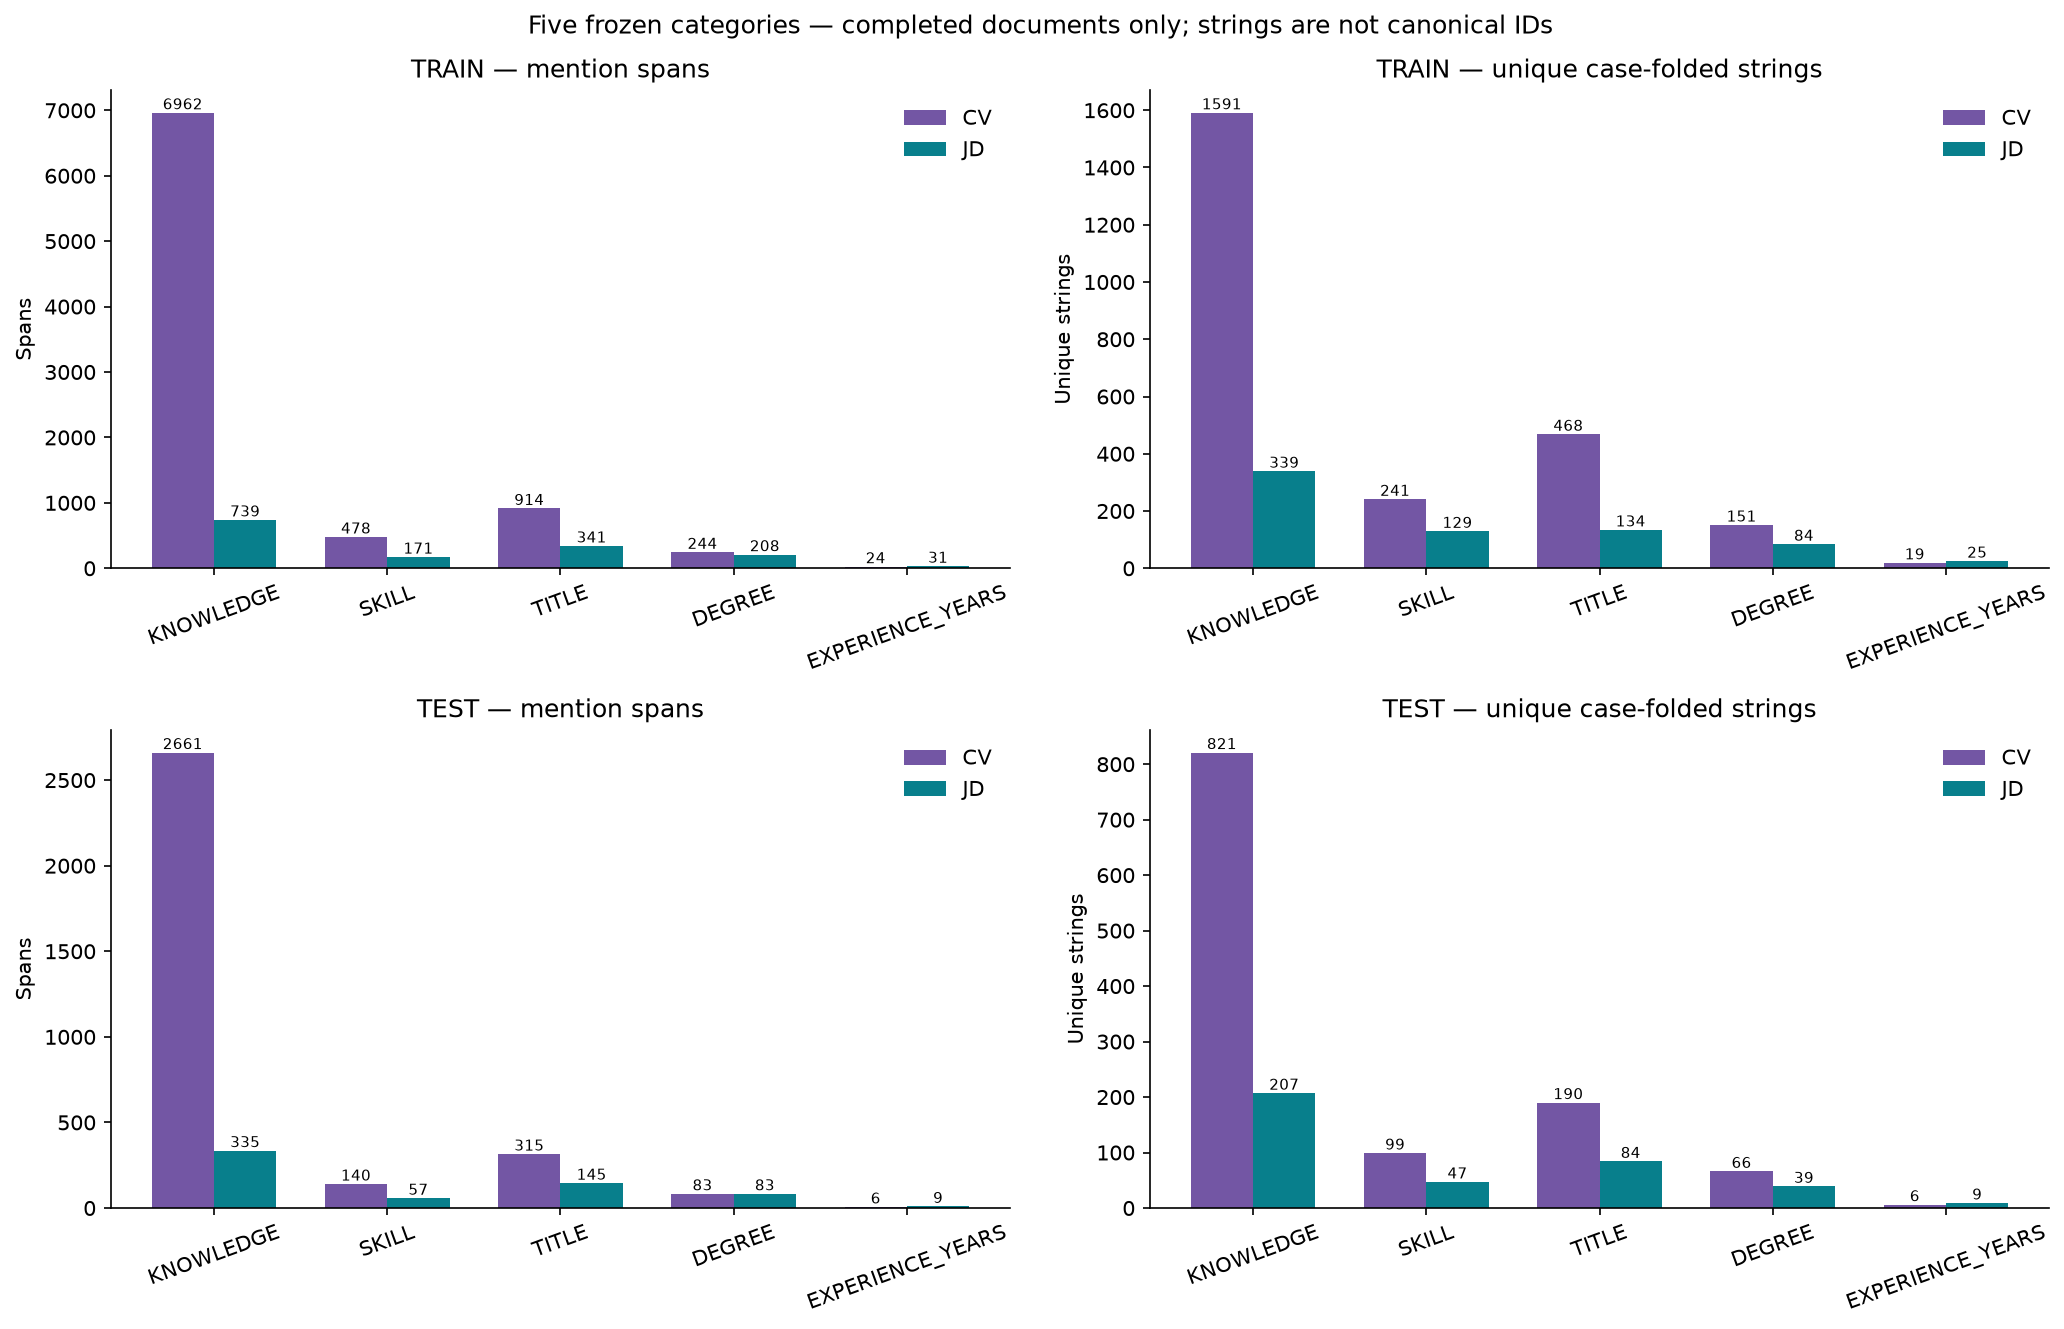

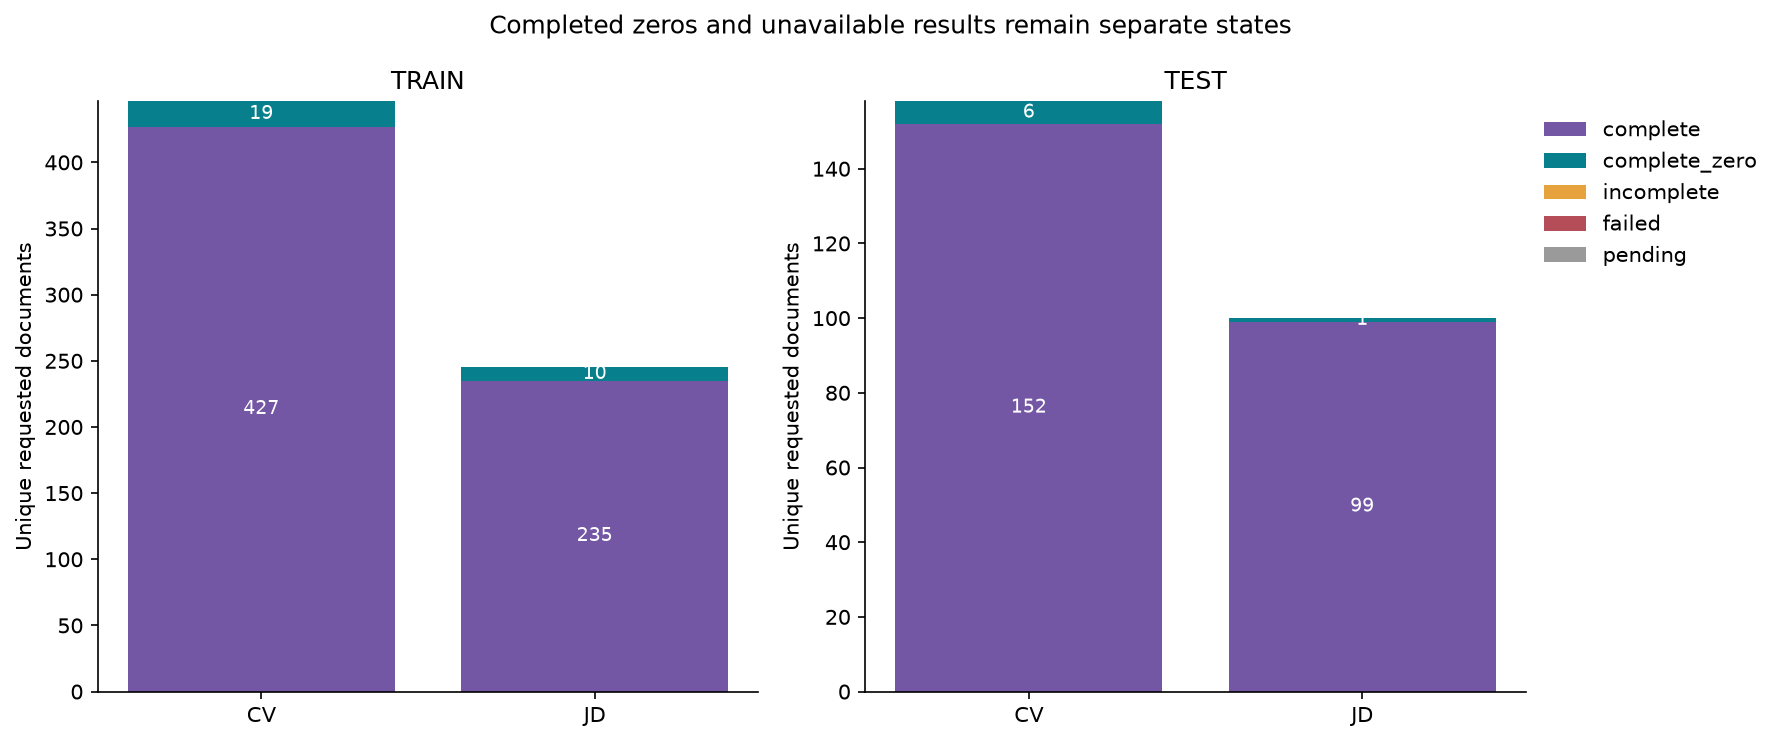

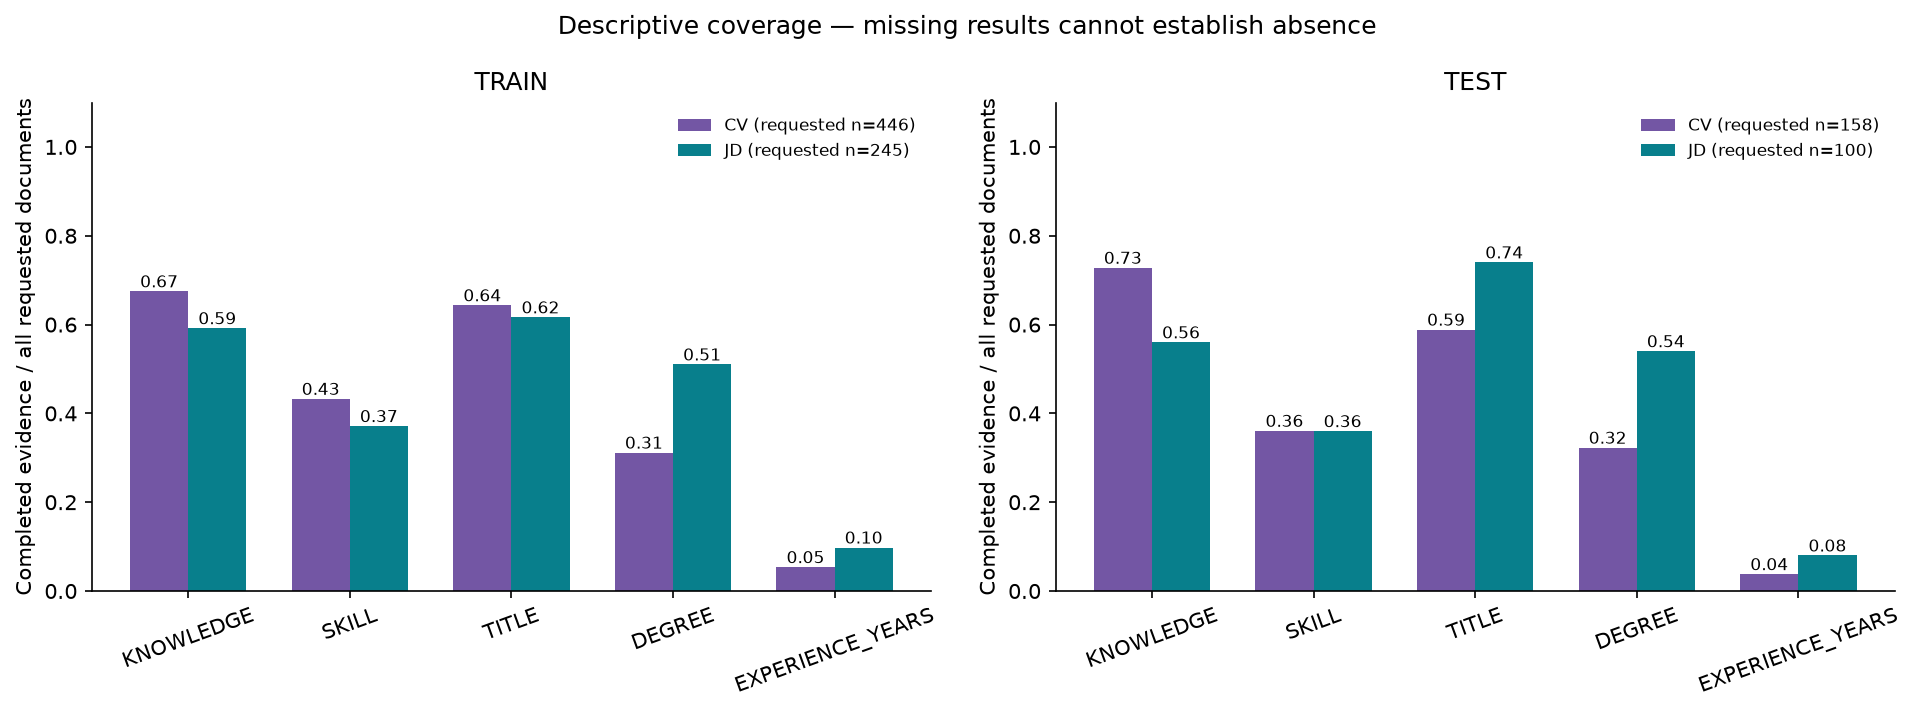

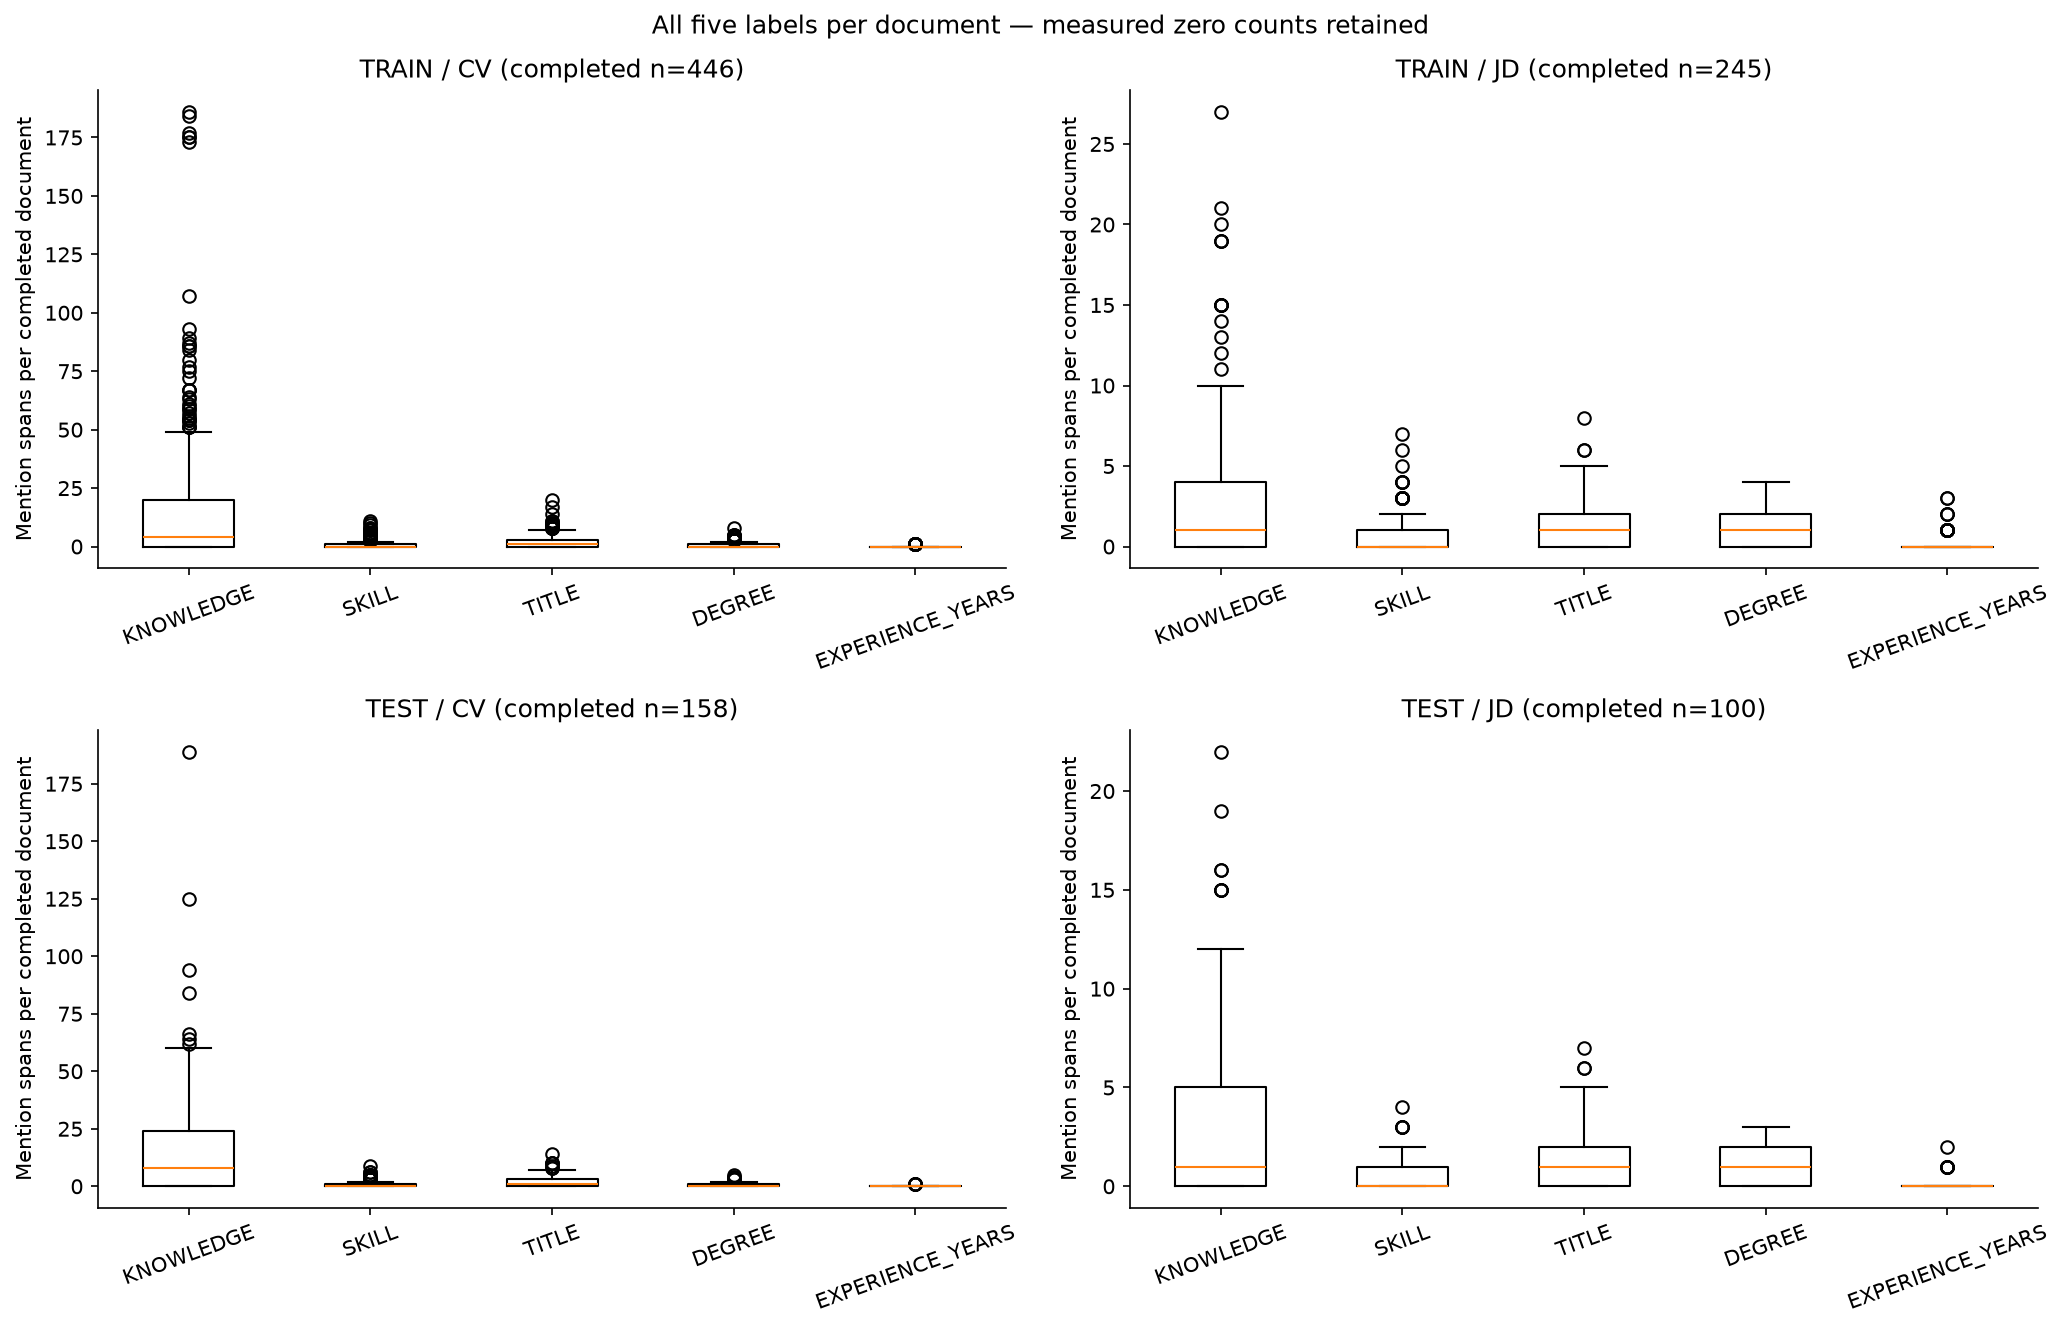

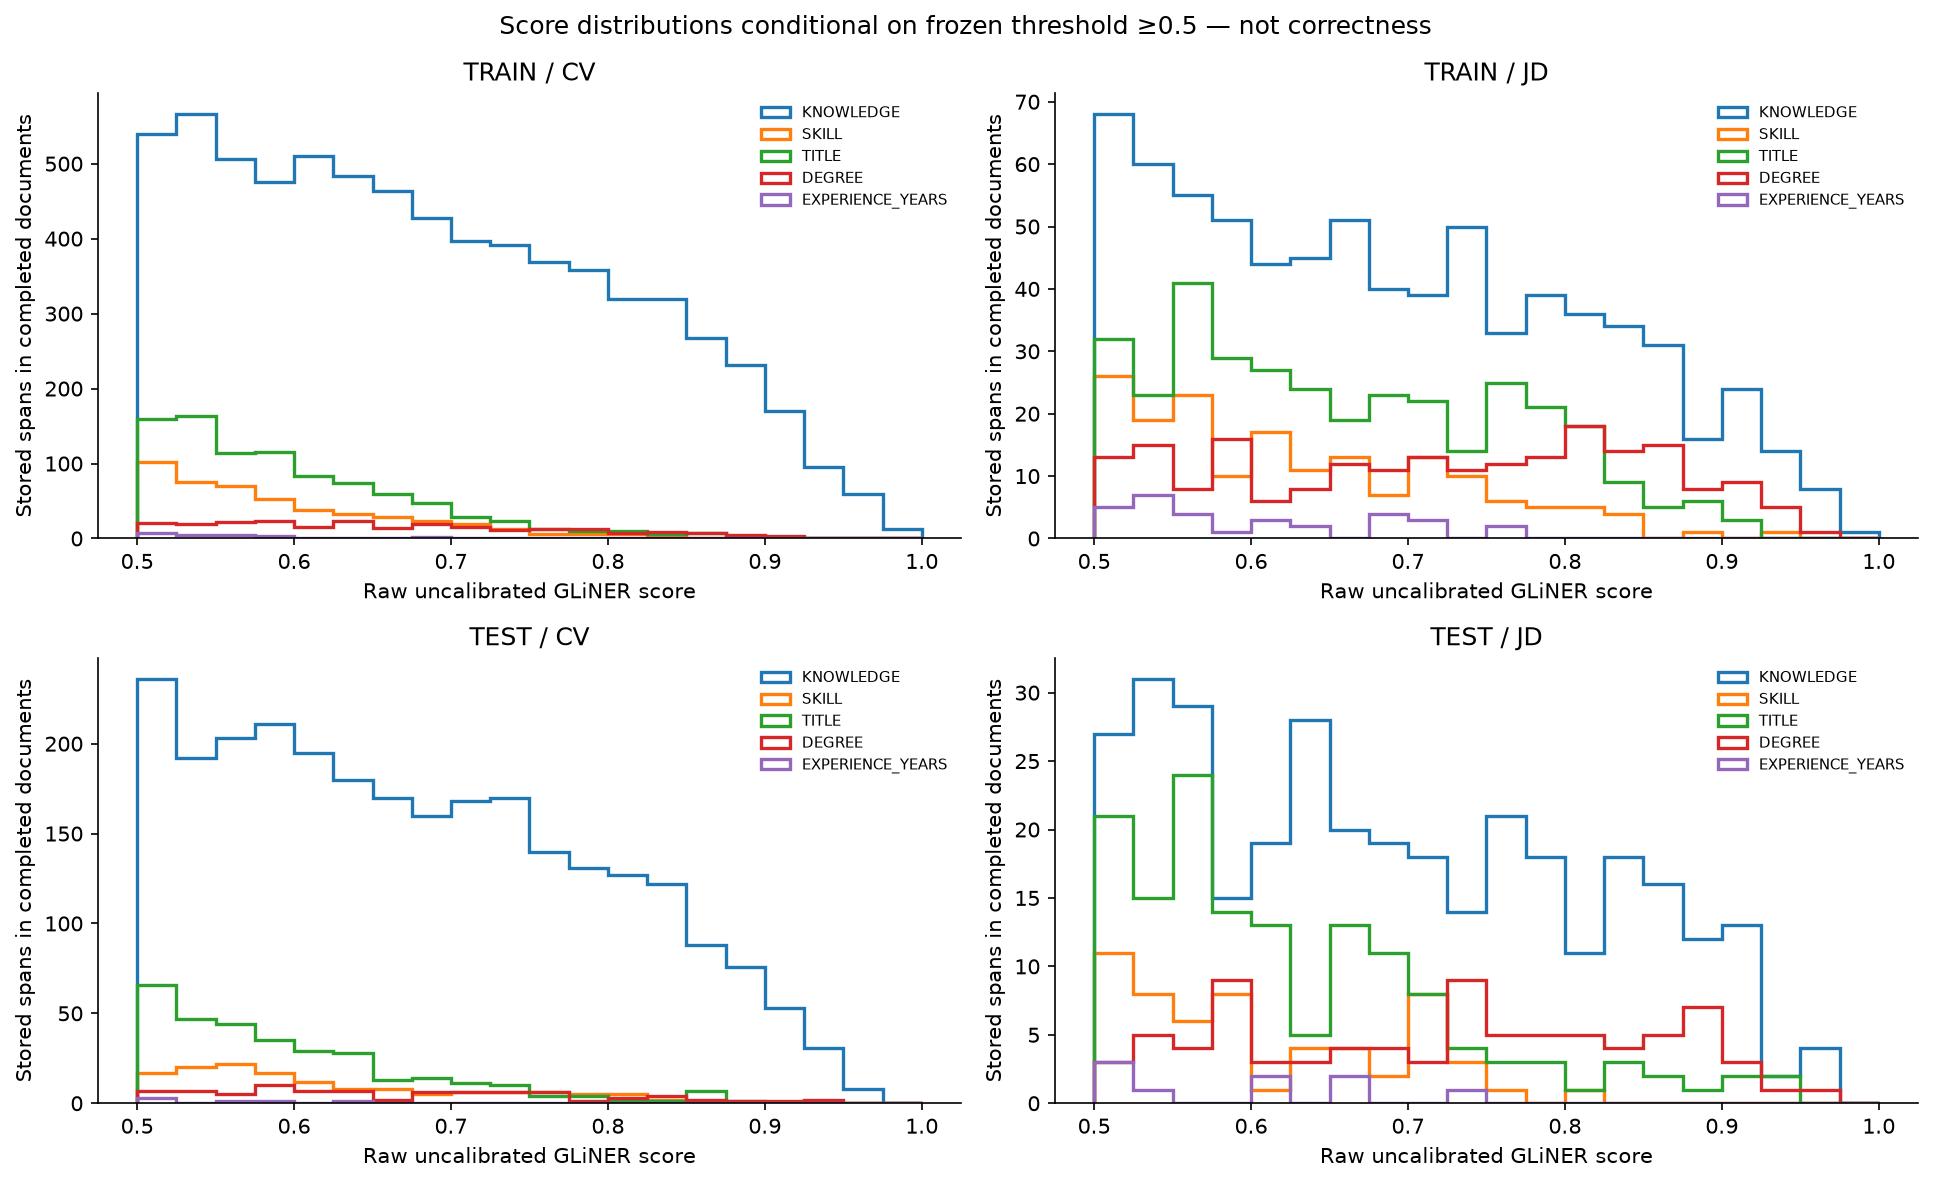

medium


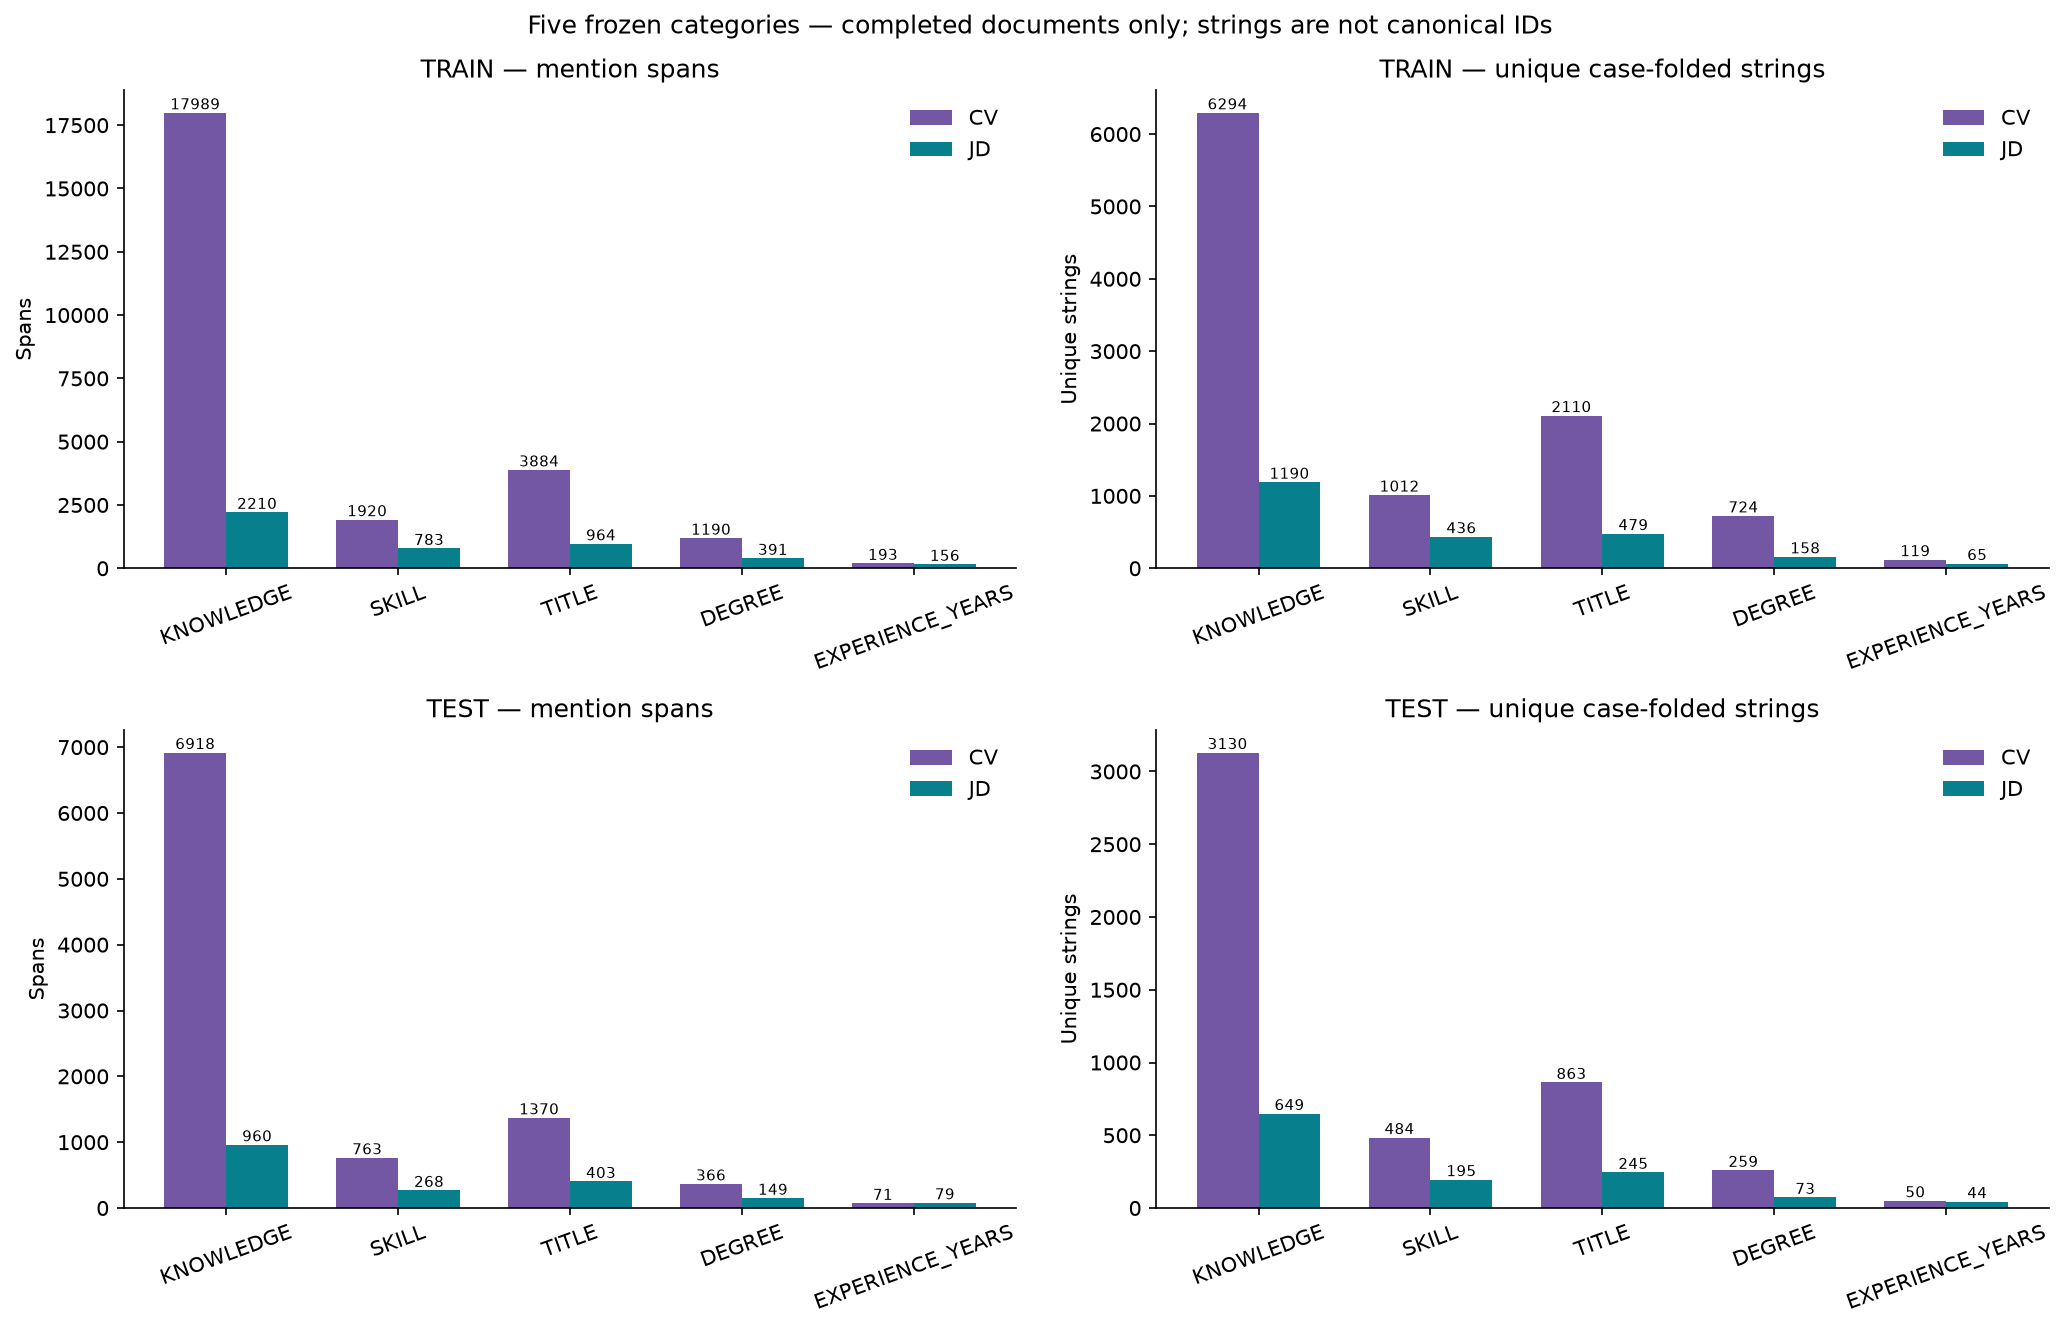

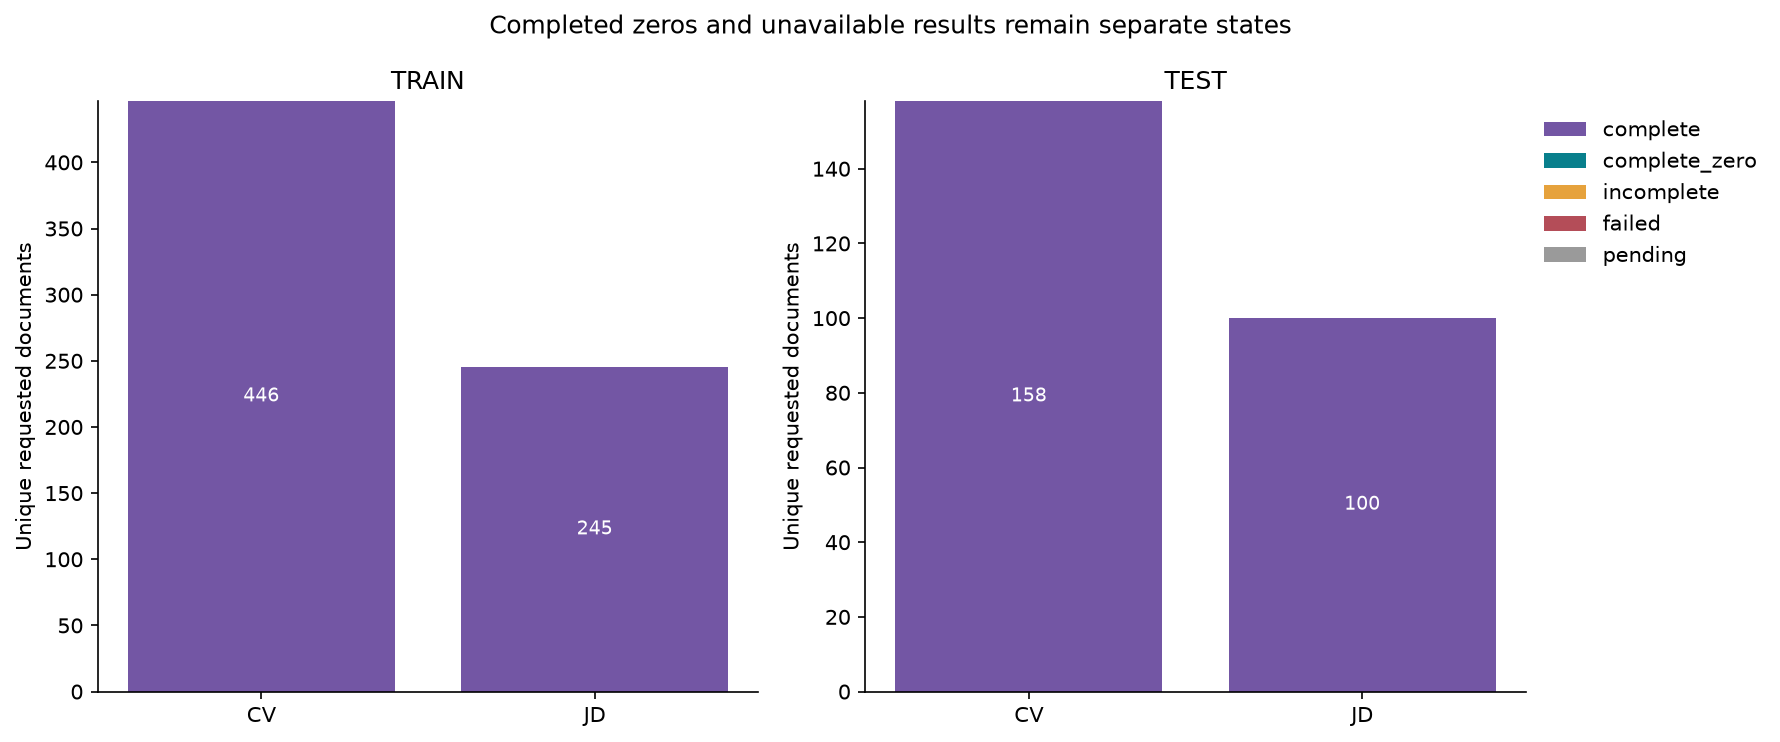

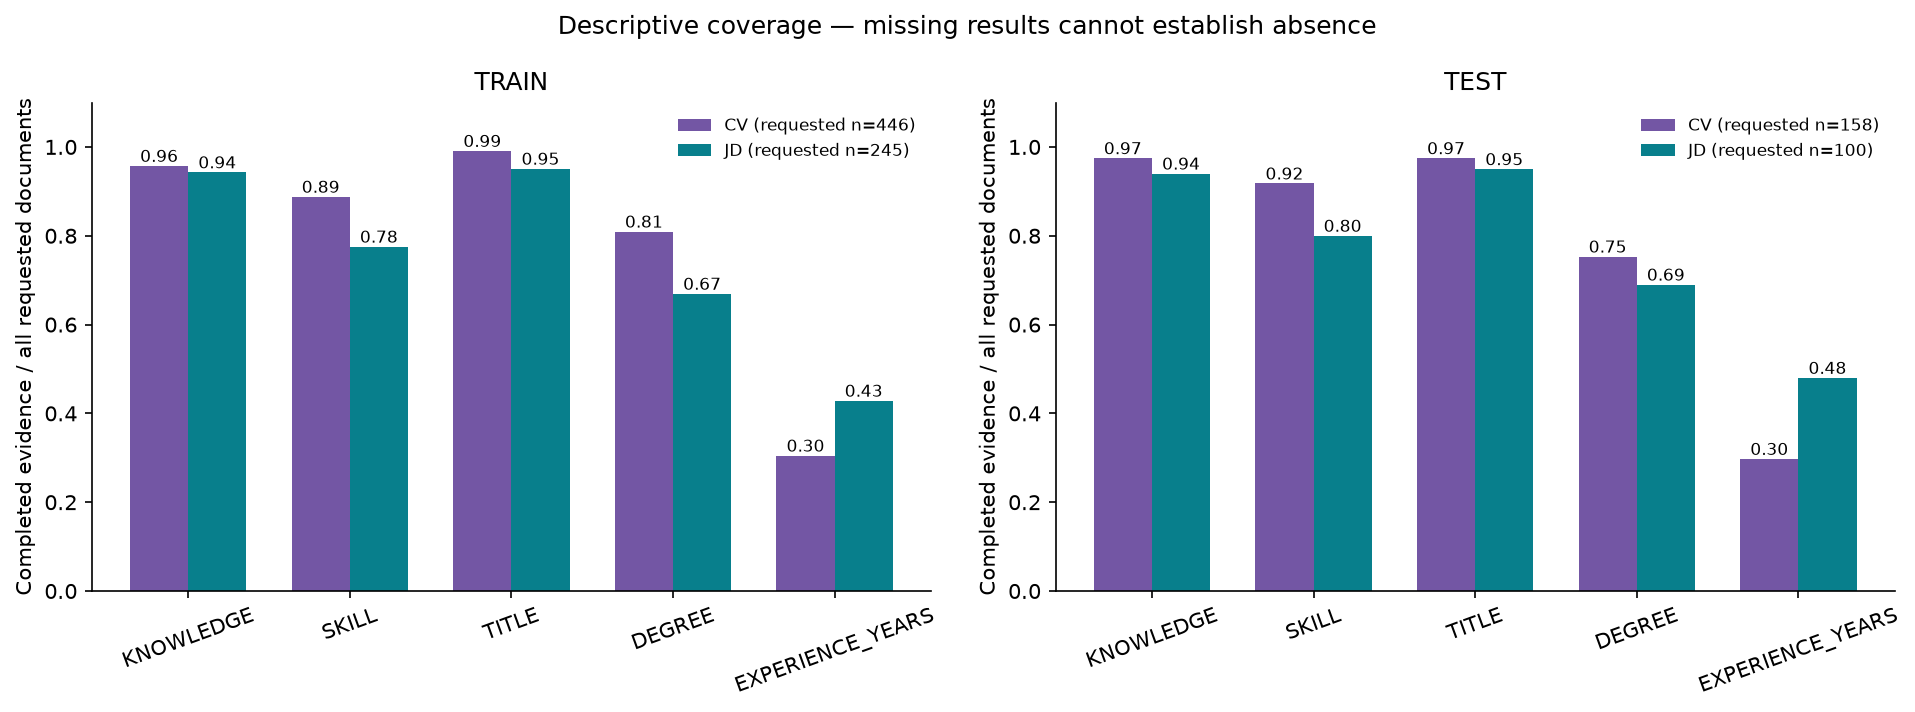

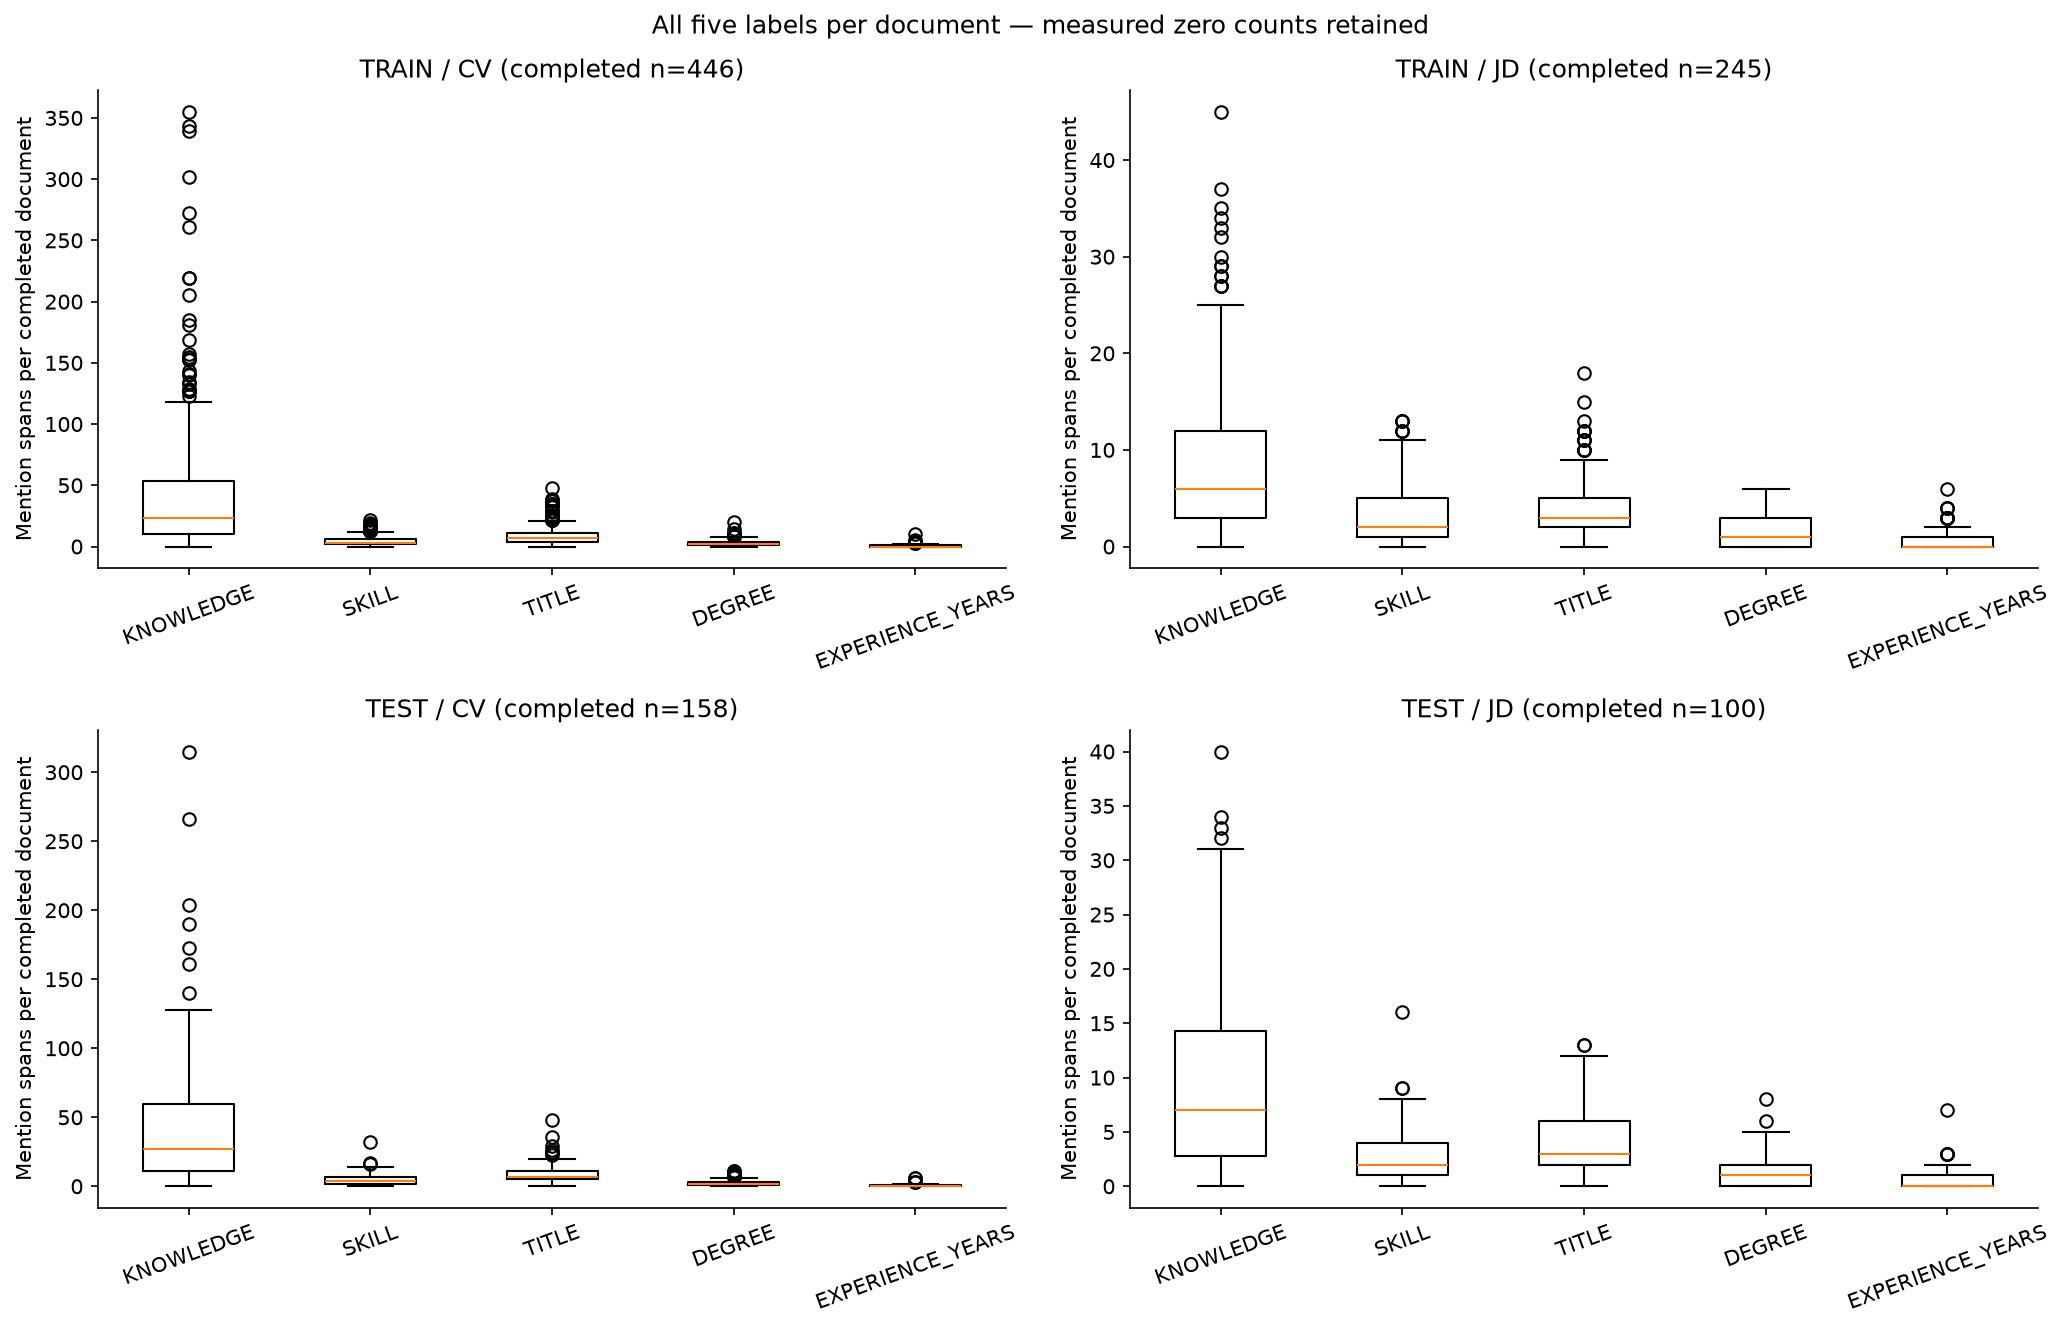

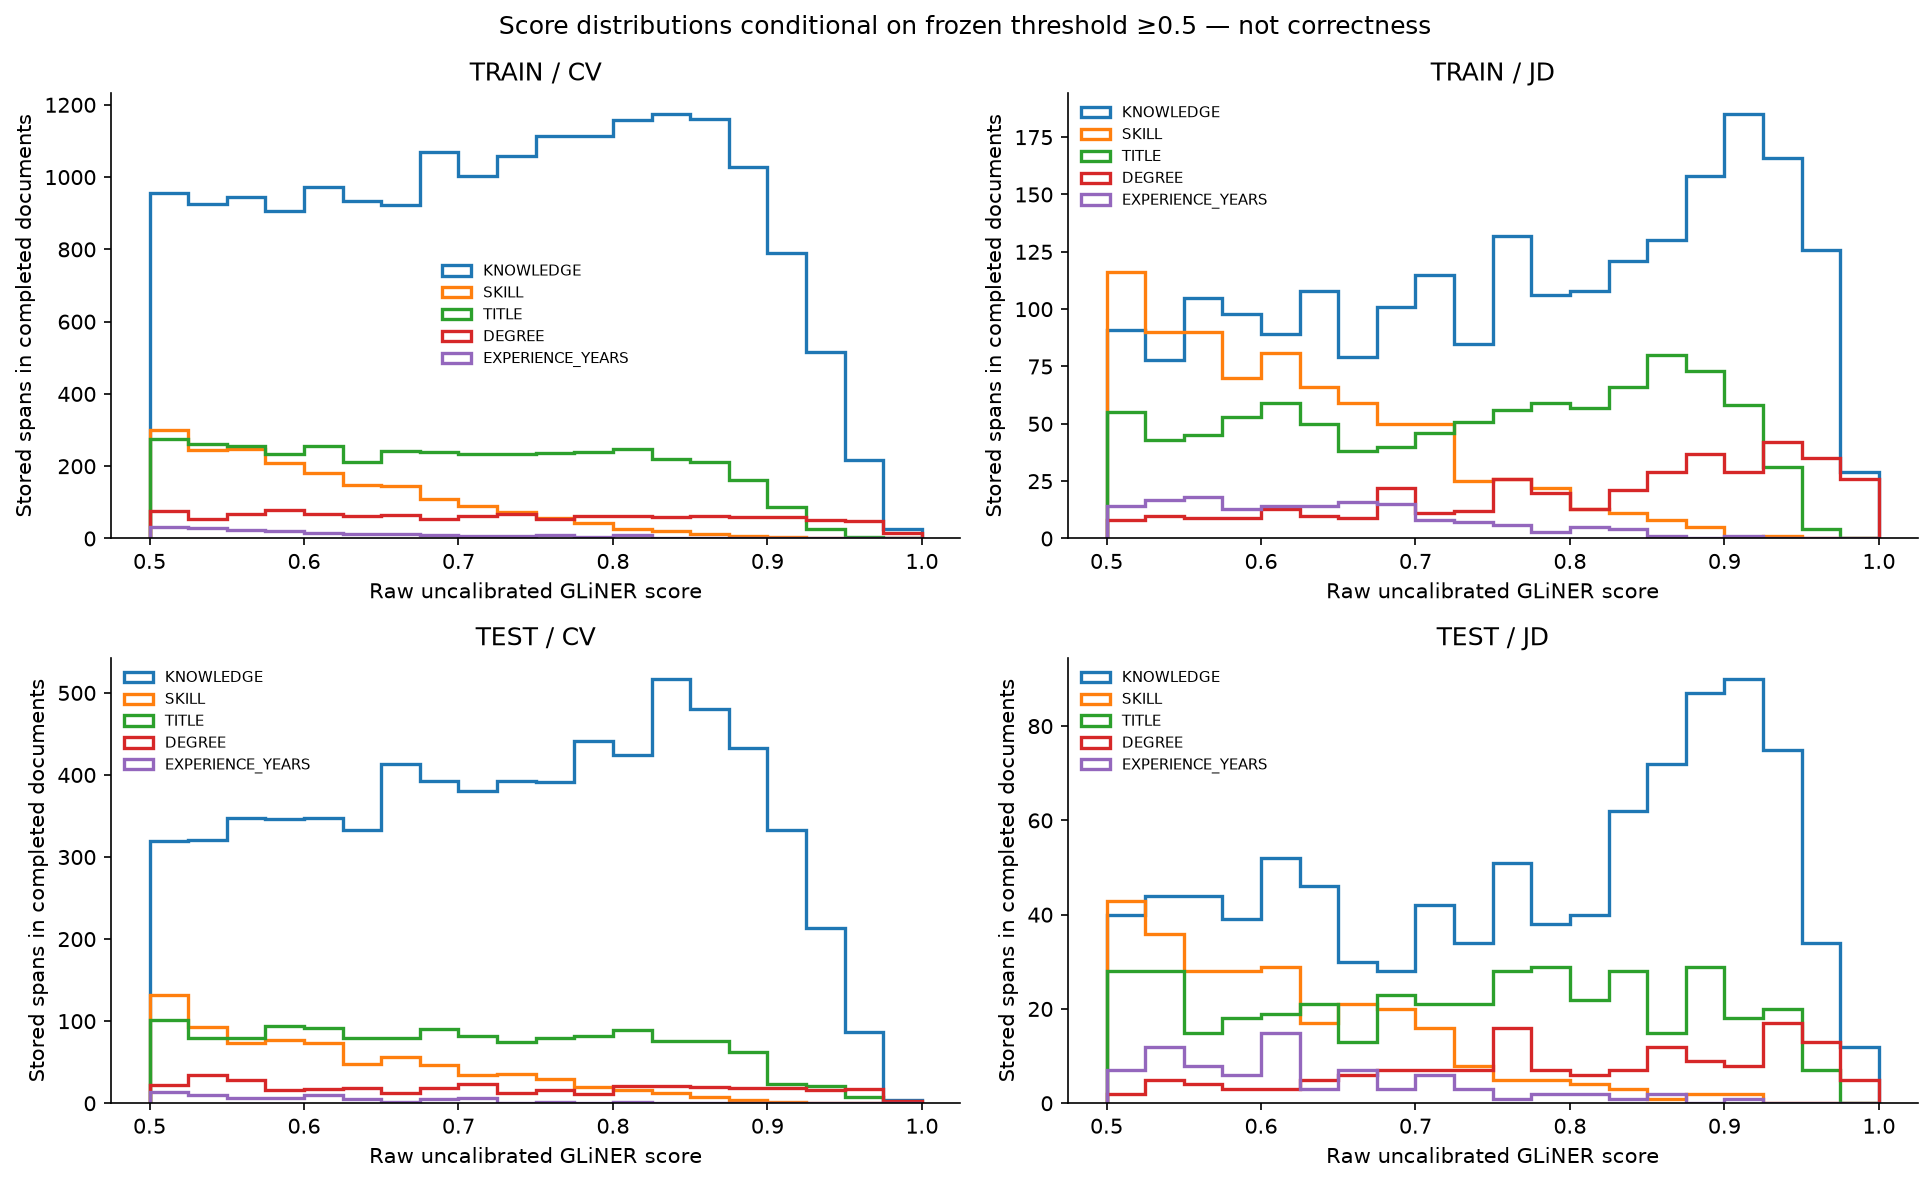

In [14]:
charts = {"small": save_fit_charts(baseline, report_dir / "small"),
          "medium": save_fit_charts(medium, report_dir / "medium")}
for model, paths in charts.items():
    print(model)
    for path in paths.values():
        display(Image(filename=path))

## Interpretation

Compare completion, failures, timing, fallback usage and category distributions. More spans can mean better recall, more false positives, or both. Compatible entity-span gold and a separately approved controlled ablation are required to quantify accuracy or isolate chunking. Completed zeros are measured; incomplete/failed documents remain unknown.